In [1]:
%pip install -q tensorflow numpy pandas matplotlib seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras import layers, ops, applications, callbacks, losses, metrics, optimizers

from PIL import Image
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

from prepare_data import CLASSES, DEFAULT_DIR, DX_NAMES, HAM_CLASSES, load_labels
from pipeline import CLASS_IDX, HAM_IDX, class_weights, make_datasets

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026101904


GPUs: []


# Carregamento e exploração dos dados

In [3]:
# Base única gerada pelo prepare_data.py (ver README):
# train/val = ISIC 2019 (HAM10000 + BCN_20000 + MSK), 8 classes
# test      = ISIC 2018 Task 3, rotulado só nas 7 classes do HAM (coluna dx_ham)
# unlabeled = resto do teste do ISIC 2019, sem rótulo
df = load_labels()
train_df, val_df, test_df, unlabeled_df = (
    df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test", "unlabeled"]
)
print({s: len(d) for s, d in zip(["train", "val", "test", "unlabeled"],
                                 [train_df, val_df, test_df, unlabeled_df])})
df.head()

{'train': 21486, 'val': 3845, 'test': 1511, 'unlabeled': 6726}


,image_id,file_id,lesion_id,split,dx,dx_ham,dx_name,malignant,source,dataset,dx_type,age_approx,sex,site,image_path,mask_path
0,ISIC_0000000,ISIC_0000000,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,55.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
1,ISIC_0000001,ISIC_0000001,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
2,ISIC_0000002,ISIC_0000002,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,60.0,female,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN
3,ISIC_0000003,ISIC_0000003,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,male,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
4,ISIC_0000004,ISIC_0000004,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,80.0,male,posterior torso,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN


In [4]:
# Classes por split (no teste, o rótulo disponível é o dx_ham: akiec = ak + scc)
labeled = df[df["split"] != "unlabeled"]
pd.crosstab(labeled["dx"].fillna(labeled["dx_ham"]), labeled["split"], margins=True)

split,test,train,val,All
dx,,,,
ak,0,719,148,867
akiec,43,0,0,43
bcc,93,2824,499,3416
bkl,217,2251,373,2841
df,44,200,39,283
mel,171,3855,667,4693
nv,908,10893,1982,13783
scc,0,533,95,628
vasc,35,211,42,288


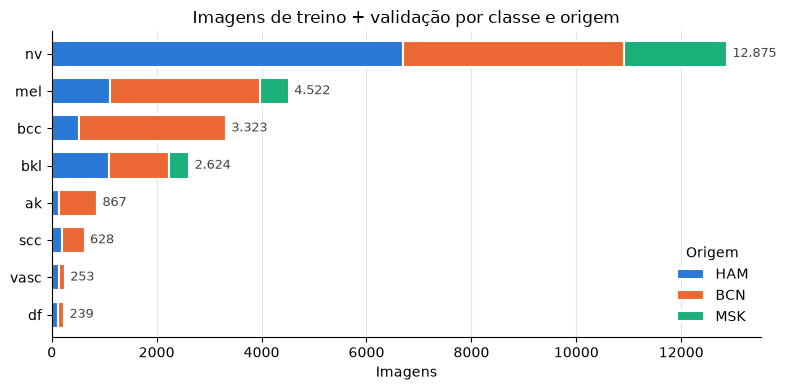

dx,ak,bcc,bkl,df,mel,nv,scc,vasc
source,,,,,,,,
HAM,1.3,5.1,11.0,1.1,11.1,66.9,2.0,1.4
BCN,5.9,22.6,9.2,1.0,23.0,33.9,3.5,0.9
MSK,0.0,0.0,13.3,0.0,19.0,67.7,0.0,0.0


In [5]:
# Treino + validação por classe e origem
SOURCES = ["HAM", "BCN", "MSK"]
SOURCE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

trainval = df[df["split"].isin(["train", "val"])]
counts = pd.crosstab(trainval["dx"], trainval["source"])[SOURCES]
counts = counts.loc[counts.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.barh(stacked=True, color=SOURCE_COLORS, edgecolor="white", linewidth=1.5, width=0.7, ax=ax)
for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 100, i, f"{total:,}".replace(",", "."), va="center", fontsize=9, color="#444")
ax.set(xlabel="Imagens", ylabel="", title="Imagens de treino + validação por classe e origem")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(title="Origem", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

# Proporção (%) de cada classe dentro de cada origem
display((pd.crosstab(trainval["source"], trainval["dx"], normalize="index") * 100).round(1).loc[SOURCES, CLASSES])

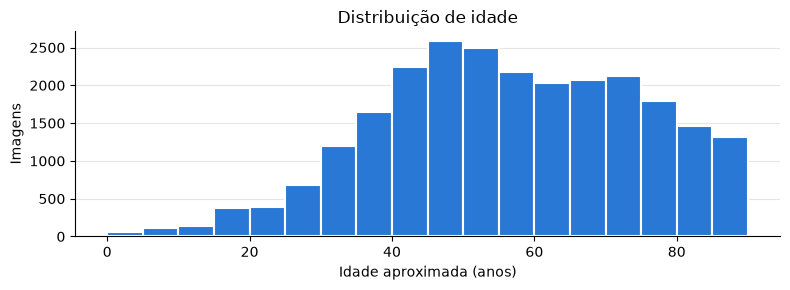

Faltantes (%):
age_approx     1.7
sex            1.5
site          10.2


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
site,,,,,,,,
(vazio),22,72,273,3,127,2049,6,31
anterior torso,92,1114,445,43,1331,3699,113,78
head/neck,598,1131,1001,0,880,767,174,36
lateral torso,0,0,6,0,14,34,0,0
lower extremity,66,462,412,138,796,2876,182,58
oral/genital,0,0,16,1,19,69,0,2
palms/soles,6,0,7,0,201,168,13,3
posterior torso,4,186,230,2,430,1888,25,22
upper extremity,79,358,234,52,724,1325,115,23


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
sex,,,,,,,,
(vazio),3,6,23,0,81,271,0,0
female,406,1317,1134,117,1980,6379,203,125
male,458,2000,1467,122,2461,6225,425,128


In [6]:
# Metadados clínicos (treino + validação)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(trainval["age_approx"].dropna(), bins=np.arange(0, 95, 5), color="#2a78d6", edgecolor="white", linewidth=1.5)
ax.set(xlabel="Idade aproximada (anos)", ylabel="Imagens", title="Distribuição de idade")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("Faltantes (%):")
print((trainval[["age_approx", "sex", "site"]].isna().mean() * 100).round(1).to_string())
display(pd.crosstab(trainval["site"].fillna("(vazio)"), trainval["dx"])[CLASSES])
display(pd.crosstab(trainval["sex"].fillna("(vazio)"), trainval["dx"])[CLASSES])

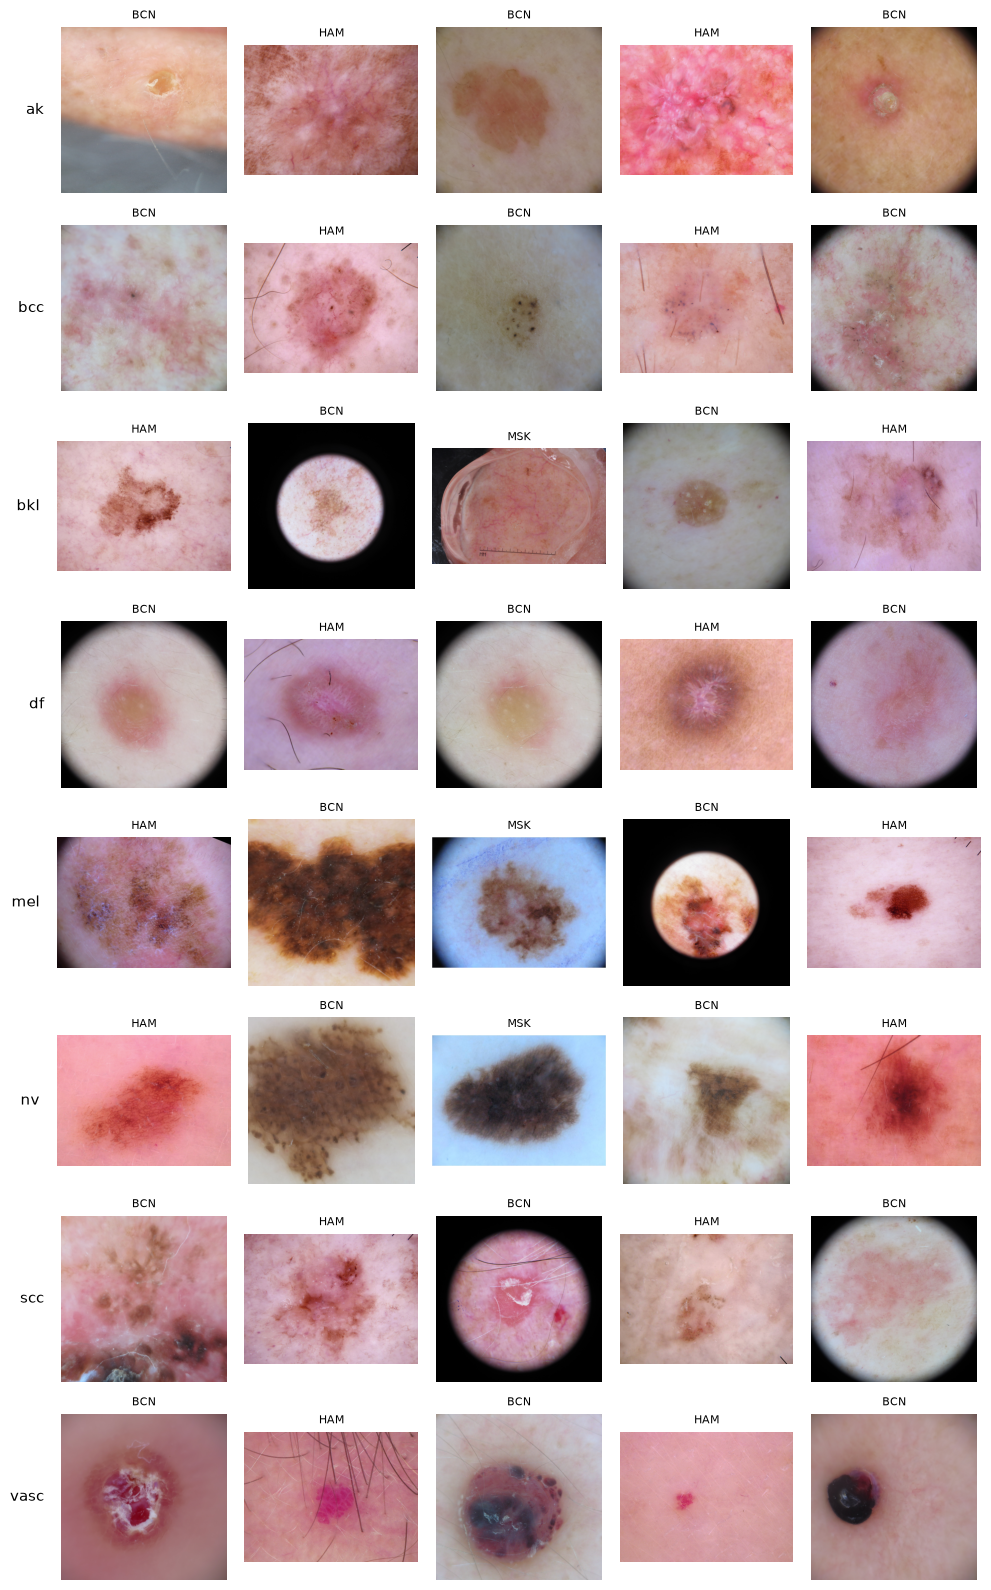

source
BCN                                   {(1024, 1024): 50}
HAM                                     {(600, 450): 50}
MSK    {(1024, 680): 19, (1024, 768): 10, (1024, 685)...
Name: size, dtype: object

In [7]:
# Exemplos de cada classe, misturando as origens
N_EXAMPLES = 5
fig, axes = plt.subplots(len(CLASSES), N_EXAMPLES, figsize=(2 * N_EXAMPLES, 2 * len(CLASSES)))
for row, dx in zip(axes, CLASSES):
    pool = train_df[train_df["dx"] == dx].groupby("source").head(N_EXAMPLES)
    sample = pool.sample(min(N_EXAMPLES, len(pool)), random_state=SEED)
    for ax in row:
        ax.axis("off")
    for ax, r in zip(row, sample.itertuples()):
        ax.imshow(Image.open(r.image_path))
        ax.set_title(r.source, fontsize=8)
    row[0].text(-0.1, 0.5, dx, transform=row[0].transAxes, ha="right", va="center", fontsize=11)
plt.tight_layout()
plt.show()

# Tamanho das imagens por origem (amostra)
sizes = train_df.groupby("source").sample(50, random_state=SEED)
sizes["size"] = [Image.open(p).size for p in sizes["image_path"]]
sizes.groupby("source")["size"].agg(lambda s: s.value_counts().head(3).to_dict())

In [8]:
# Datasets do TensorFlow (pipeline.py, o mesmo código usado no Kaggle).
# train/val: rótulos em CLASSES; test: rótulos em HAM_CLASSES; unlabeled: sem rótulo
IMG_SIZE = 224
BATCH_SIZE = 32

ds = make_datasets(df, img_size=IMG_SIZE, batch_size=BATCH_SIZE)
train_ds, val_ds, test_ds, unlabeled_ds = ds["train"], ds["val"], ds["test"], ds["unlabeled"]

# pesos para compensar o desbalanceamento (nv domina o treino)
class_weight = class_weights(train_df["dx"])

images, labels = next(iter(train_ds))
print("batch:", images.shape, labels.shape)
print("pesos:", {CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

batch: (32, 224, 224, 3) (32,)
pesos: {'ak': 3.74, 'bcc': 0.95, 'bkl': 1.19, 'df': 13.43, 'mel': 0.7, 'nv': 0.25, 'scc': 5.04, 'vasc': 12.73}


# Modelo

# Treino

# Teste

# Registro de iterações